# 01 · Análisis exploratorio — Favorita Demand Forecast

**Pregunta gancho:** ¿cuánto va a vender cada tienda de un supermercado ecuatoriano las próximas semanas, y qué tanto mueven las ventas los feriados, las promociones y la quincena?

Datos: competencia de Kaggle *Store Sales – Time Series Forecasting* (Corporación Favorita, Ecuador), 2013-01-01 a 2017-08-15, 54 tiendas × 33 familias. Se lee desde la capa **gold** de DuckDB construida por `src/pipeline.py`.

> **Nota de método.** Los "efectos" de este notebook comparan cada día (o celda) con días normales comparables del mismo año, mes y día de la semana. Son **asociaciones observadas, no efectos causales probados**: otras cosas pueden cambiar a la vez (clima, campañas, aperturas de tiendas).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import analysis as a, config

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
ACC, GRY, BLU = "#B4532A", "#8A8478", "#2F5D7C"
pd.set_option("display.float_format", "{:,.3f}".format)
con = duckdb.connect(str(config.DUCKDB_PATH), read_only=True)
daily = a.daily_totals(con)
print(f"{len(daily):,} días con ventas totales; {daily.date.min():%Y-%m-%d} a {daily.date.max():%Y-%m-%d}")

1,679 días con ventas totales; 2013-01-02 a 2017-08-15


## 1. Tendencia, crecimiento y un problema de registro

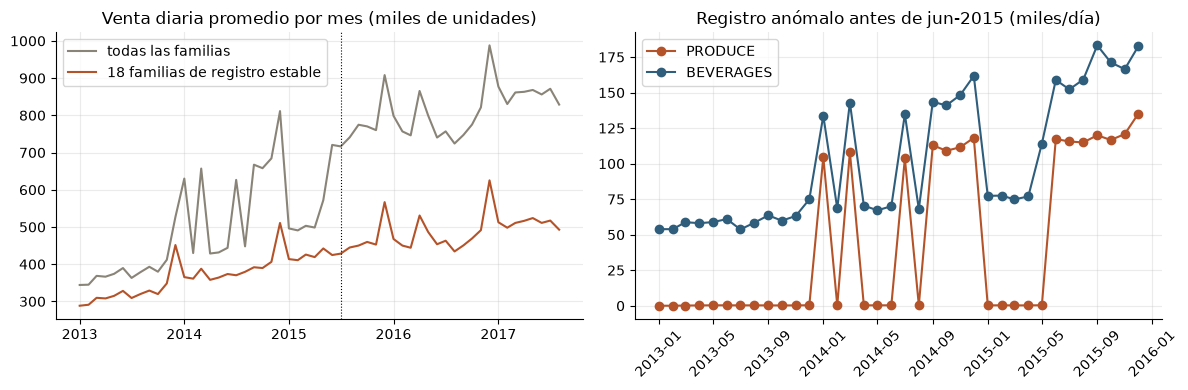

Familias estables: 18 (66% de las ventas) | meses-familia anómalos antes de jul-2015: 247 en 15 familias


,year,growth_estables,growth_todas
0,2013,—,—
1,2014,+19.8%,+41.4%
2,2015,+15.4%,+13.0%
3,2016,+10.1%,+33.0%
4,2017,+9.0%,+10.5%


In [2]:
estables = a.stable_families(con)
daily_st = a.daily_totals(con, estables)
reg = a.registration_by_family(con)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
m_all = daily.set_index("date").sales.resample("MS").mean() / 1e3
m_st = daily_st.set_index("date").sales.resample("MS").mean() / 1e3
ax[0].plot(m_all.index, m_all.values, color=GRY, label="todas las familias")
ax[0].plot(m_st.index, m_st.values, color=ACC, label=f"{len(estables)} familias de registro estable")
ax[0].axvline(pd.Timestamp("2015-07-01"), color="k", ls=":", lw=.8); ax[0].legend()
ax[0].set_title("Venta diaria promedio por mes (miles de unidades)")
pv = reg[reg.family.isin(["PRODUCE", "BEVERAGES"]) & (reg.month < "2016-01-01")].pivot(index="month", columns="family", values="avg_daily") / 1e3
ax[1].plot(pv.index, pv.PRODUCE, color=ACC, marker="o", label="PRODUCE"); ax[1].plot(pv.index, pv.BEVERAGES, color=BLU, marker="o", label="BEVERAGES")
ax[1].set_title("Registro anómalo antes de jun-2015 (miles/día)"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
share = daily_st.sales.sum() / daily.sales.sum()
antes = reg[reg.anomalous & (reg.month < "2015-07-01")]
print(f"Familias estables: {len(estables)} ({share:.0%} de las ventas) | meses-familia anómalos antes de jul-2015: {len(antes)} en {antes.family.nunique()} familias")
comp = a.yearly_comparable(daily_st).merge(a.yearly_comparable(daily), on="year", suffixes=("_estables", "_todas"))
comp[["year", "growth_estables", "growth_todas"]].assign(**{c: comp[c].map(lambda v: f"{v:+.1%}" if pd.notna(v) else "—") for c in ["growth_estables", "growth_todas"]})

**Conclusión.** La serie total tiene caídas de hasta un tercio que se revierten al mes siguiente (feb-2014, abr–jun-2014, ene–may-2015). No son caídas de demanda: hay un **problema de registro**. PRODUCE registra prácticamente 0 en toda la cadena la mayoría de los meses hasta mayo de 2015, BEVERAGES cae a la mitad en meses alternos, y varias familias no alimentarias no tienen ventas antes de junio de 2015 (247 meses–familia anómalos antes de julio de 2015, en 15 familias).

Por eso las comparaciones entre años usan las 18 familias de registro estable (66% de las ventas) y el mismo periodo del año (1-ene a 15-ago). Así medido, el crecimiento es de +20% en 2014 (incluye aperturas: el 2-ene-2013 vendían 46 tiendas y hoy 54), +15% en 2015, +10% en 2016 y +9% en 2017. Con todas las familias, 2016 aparentaría +33%, un número inflado por el registro incompleto. Para el modelo: entrenar desde julio de 2015 (ADR 0004).

## 2. Estacionalidad semanal y mensual

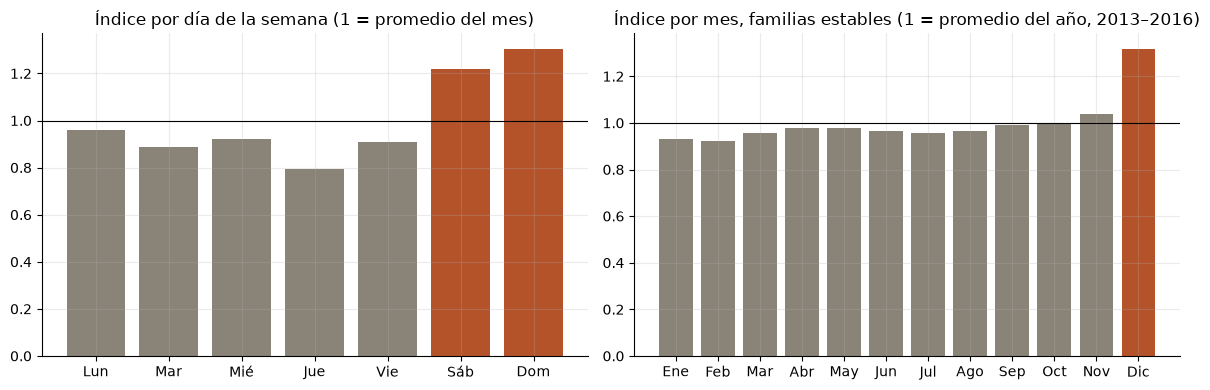

dia,Lun,Mar,Mié,Jue,Vie,Sáb,Dom
indice,0.961,0.886,0.923,0.795,0.911,1.218,1.305


In [3]:
s = a.seasonality(daily)
s["month"] = a.seasonality(daily_st)["month"]  # el índice mensual compara meses: solo familias estables
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
ax[0].bar(dias, s["dow"].values, color=[GRY]*5 + [ACC]*2); ax[0].axhline(1, color="k", lw=.8)
ax[0].set_title("Índice por día de la semana (1 = promedio del mes)")
meses = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
ax[1].bar(meses, s["month"].values, color=[GRY]*11 + [ACC]); ax[1].axhline(1, color="k", lw=.8)
ax[1].set_title("Índice por mes, familias estables (1 = promedio del año, 2013–2016)")
plt.tight_layout(); plt.show()
pd.DataFrame({"dia": dias, "indice": s["dow"].values}).set_index("dia").T

**Conclusión.** El fin de semana manda: el domingo vende 31% más que el promedio del mes y el sábado 22% más; el jueves es el día más flojo (−21%). En el año (familias estables, para no mezclar el problema de registro), diciembre está 32% sobre el promedio anual, noviembre 4% arriba, y enero y febrero son los meses más flojos (−7% y −8%). Día de la semana y mes deben entrar como variables del modelo.

## 3. Diciembre y Navidad

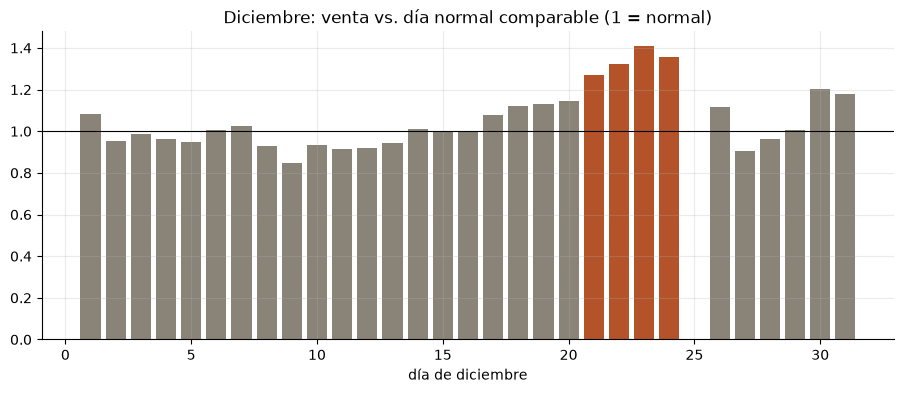

,date,sales
1542,2017-04-01,"1,463,083.962"
1453,2017-01-02,"1,402,306.371"
1606,2017-06-04,"1,376,511.520"
1196,2016-04-18,"1,345,920.605"
1572,2017-05-01,"1,306,699.367"
1634,2017-07-02,"1,296,379.218"
1445,2016-12-23,"1,282,145.517"
1426,2016-12-04,"1,276,195.036"


In [4]:
dic = daily[(daily.month == 12) & (daily.year <= 2016)].copy()
dic["day"] = dic.date.dt.day
perfil = dic.groupby("day").ratio.mean()
fig, ax = plt.subplots()
ax.bar(perfil.index, perfil.values, color=[ACC if d in (21,22,23,24) else GRY for d in perfil.index])
ax.axhline(1, color="k", lw=.8); ax.set_title("Diciembre: venta vs. día normal comparable (1 = normal)"); ax.set_xlabel("día de diciembre")
plt.show()
top = daily.nlargest(8, "sales")[["date", "sales"]]; top

**Conclusión.** Los días previos a Navidad (21 al 24 de diciembre, marcados como *Additional* en el calendario de feriados) venden alrededor de 24% más que un día normal comparable. El 25 de diciembre las tiendas cierran (no hay filas en los datos) y el 1 de enero casi no hay ventas, así que se excluye de los promedios. Curiosamente, los días récord del periodo no están en diciembre sino en fechas como el 1-abr-2017 o el 2-ene-2017: el crecimiento de 2017 pesa más que la estacionalidad.

## 4. Feriados nacionales y locales

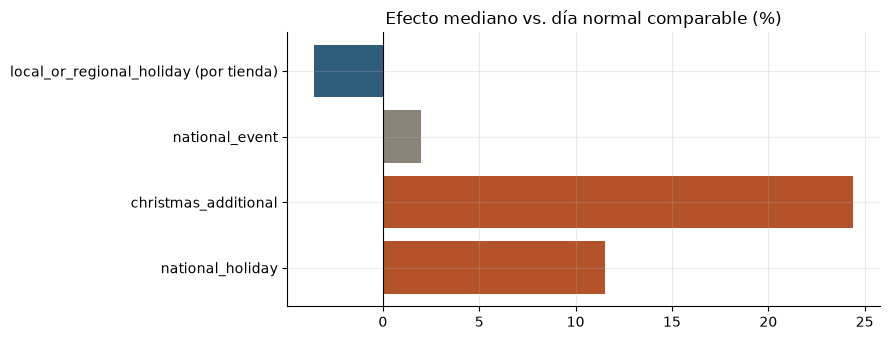

,effect,mean_pct,median_pct,n_days
0,national_holiday,0.162,0.115,46
1,christmas_additional,0.240,0.244,28
2,national_event,0.046,0.020,54
0,local_or_regional_holiday (por tienda),-0.016,-0.036,354


In [5]:
h = a.holiday_effects(daily)
loc = a.local_holiday_effect(con)
h = pd.concat([h, pd.DataFrame([{"effect": "local_or_regional_holiday (por tienda)", "mean_pct": loc["mean_pct"],
                                 "median_pct": loc["median_pct"], "n_days": loc["n_store_days"]}])])
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(h.effect, h.median_pct * 100, color=[ACC, ACC, GRY, BLU]); ax.axvline(0, color="k", lw=.8)
ax.set_title("Efecto mediano vs. día normal comparable (%)"); plt.tight_layout(); plt.show()
h

**Conclusión.** En un feriado nacional (aplicando traslados y puentes) la venta total es en mediana 12% mayor que en un día normal del mismo mes y día de la semana (media +16%, 46 días). Los días previos a Navidad suben 24%. Los eventos nacionales (Mundial, Black Friday, réplicas del terremoto) apenas se mueven (+2% en mediana). En cambio, el feriado local o regional, medido en la tienda de esa ciudad o provincia, se asocia con una venta ligeramente **menor** (−3.6% en mediana, 354 días-tienda): mucha gente sale de la ciudad. Por eso el modelo distingue feriado nacional y feriado local por tienda.

## 5. Promociones por familia

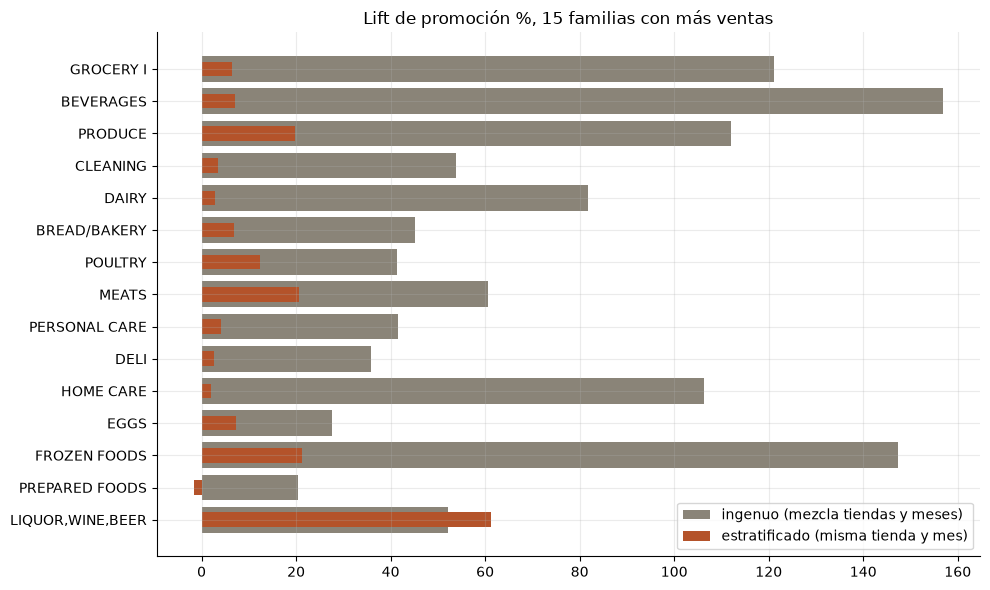

Lift estratificado ponderado por ventas: +9.0%


,family,naive_lift,stratified_lift,n_cells,sales
0,GROCERY I,1.211,0.065,678.000,"269,947,507.640"
1,BEVERAGES,1.568,0.070,946.000,"184,683,861.000"
2,PRODUCE,1.121,0.198,"1,425.000","116,029,340.842"
3,CLEANING,0.538,0.034,"1,096.000","75,211,216.000"
4,DAIRY,0.817,0.029,"1,282.000","53,415,585.000"
5,BREAD/BAKERY,0.452,0.069,"1,467.000","33,296,678.364"
6,POULTRY,0.413,0.123,"2,024.000","25,592,459.349"
7,MEATS,0.607,0.205,"2,022.000","23,102,941.982"
8,PERSONAL CARE,0.415,0.042,"1,154.000","19,698,811.000"
9,DELI,0.358,0.026,"1,512.000","19,080,971.827"


In [6]:
p = a.promo_lift(con)
top = p.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.family, top.naive_lift * 100, color=GRY, label="ingenuo (mezcla tiendas y meses)")
ax.barh(top.family, top.stratified_lift * 100, color=ACC, height=.45, label="estratificado (misma tienda y mes)")
ax.set_title("Lift de promoción %, 15 familias con más ventas"); ax.legend(); plt.tight_layout(); plt.show()
peso = (p.stratified_lift * p.sales).sum() / p.sales.sum()
print(f"Lift estratificado ponderado por ventas: {peso:+.1%}")
p.head(10)

**Conclusión.** La comparación ingenua exagera muchísimo: en GROCERY I sugiere que con promoción se vende 121% más, pero comparando dentro de la misma tienda y el mismo mes el lift baja a 6.5%. Pasa porque las promociones crecieron con el tiempo y se concentran en tiendas grandes, que ya venden más. Ponderado por ventas, el lift estratificado es de alrededor de +9%; las familias frescas como PRODUCE (+20%), MEATS (+21%) y POULTRY (+12%) responden más que las básicas como DAIRY (+3%) o CLEANING (+3%). **Sigue siendo asociación, no causalidad**: no sabemos qué productos se eligieron para promocionar ni por qué. Las promociones aparecen en los datos desde abril de 2014.

## 6. Efecto quincena

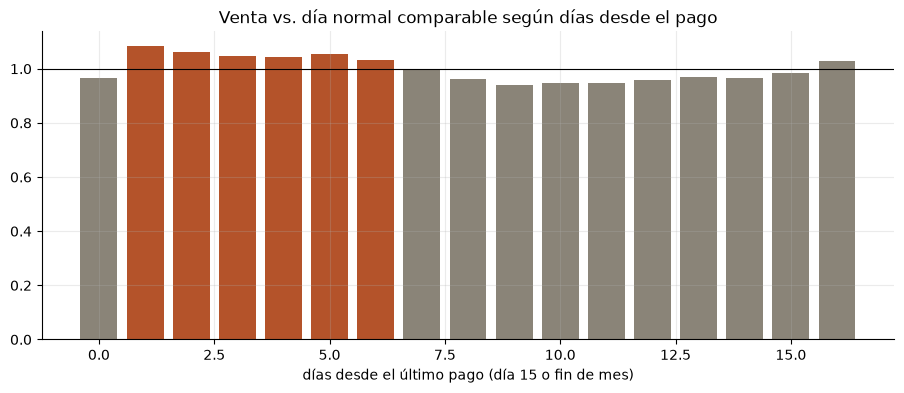

Días 1–3 después del pago vs. el resto: +8.0%


In [7]:
pp = a.payday_profile(daily)
fig, ax = plt.subplots()
ax.bar(pp.days_since_payday, pp["mean"], color=[ACC if 1 <= d <= 6 else GRY for d in pp.days_since_payday])
ax.axhline(1, color="k", lw=.8); ax.set_xlabel("días desde el último pago (día 15 o fin de mes)")
ax.set_title("Venta vs. día normal comparable según días desde el pago"); plt.show()
print(f"Días 1–3 después del pago vs. el resto: {a.payday_effect(daily):+.1%}")

**Conclusión.** El día de pago en sí no vende más (−3% frente a un día normal comparable), pero los días siguientes sí: el día 1 después del pago está 8% arriba y del 2 al 6 se mantiene entre +3% y +6%; luego la venta baja hasta 6% por debajo antes del siguiente pago. Los días 1–3 después del pago venden 8% más que el resto. La descripción del dataset advierte que el sector público paga los días 15 y último de cada mes; esto encaja, aunque también influyen pagos privados. El modelo usa `days_since_payday` y `days_to_payday`.

## 7. Terremoto del 16 de abril de 2016

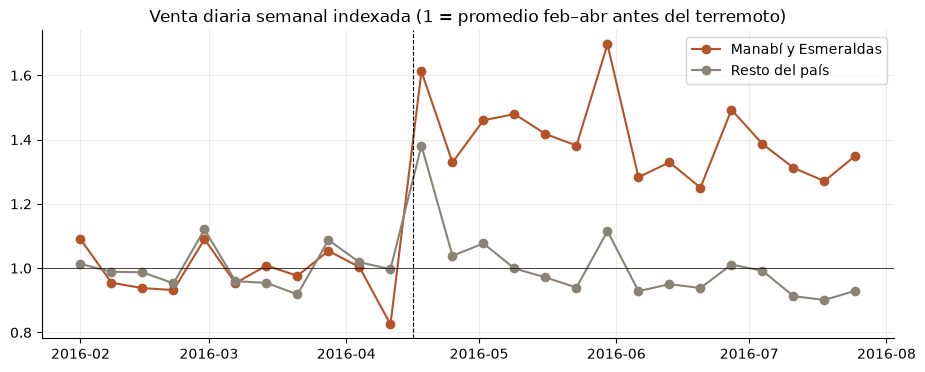

,2016 (terremoto),2015 (misma ventana)
Manabí y Esmeraldas,+40.3%,+5.9%
Resto,+14.5%,+3.5%


In [8]:
eq = a.earthquake(con)
w = eq["weekly"].pivot(index="week", columns="zone", values="avg_daily")
base = w.loc[:"2016-04-10"].mean()
fig, ax = plt.subplots()
ax.plot(w.index, w[True] / base[True], color=ACC, marker="o", label="Manabí y Esmeraldas")
ax.plot(w.index, w[False] / base[False], color=GRY, marker="o", label="Resto del país")
ax.axvline(pd.Timestamp("2016-04-16"), color="k", ls="--", lw=.8); ax.axhline(1, color="k", lw=.5)
ax.set_title("Venta diaria semanal indexada (1 = promedio feb–abr antes del terremoto)"); ax.legend(); plt.show()
pd.DataFrame({"2016 (terremoto)": [eq["zone_change_2016"], eq["rest_change_2016"]],
              "2015 (misma ventana)": [eq["zone_change_2015"], eq["rest_change_2015"]]},
             index=["Manabí y Esmeraldas", "Resto"]).map(lambda v: f"{v:+.1%}")

**Conclusión.** Comparando las 4 semanas posteriores con las 4 previas, las tiendas de Manabí y Esmeraldas (3 tiendas abiertas entonces) vendieron 40% más, y el resto del país 14% más; en la misma ventana de 2015 los cambios fueron de apenas +6% y +4%. En la semana del terremoto la zona afectada cayó (tiendas dañadas o cerradas); desde la semana del 18 de abril se disparó y siguió entre 25% y 70% por encima de su nivel previo hasta julio. El resto del país tuvo un pico de +38% esa misma semana del 18 de abril y volvió a lo normal en mayo, coherente con las donaciones de ayuda que menciona la descripción del dataset. Es un shock único: el modelo no lo puede aprender para el futuro y los cortes de validación quedan lejos de esa fecha.

## 8. Relación con el precio del petróleo

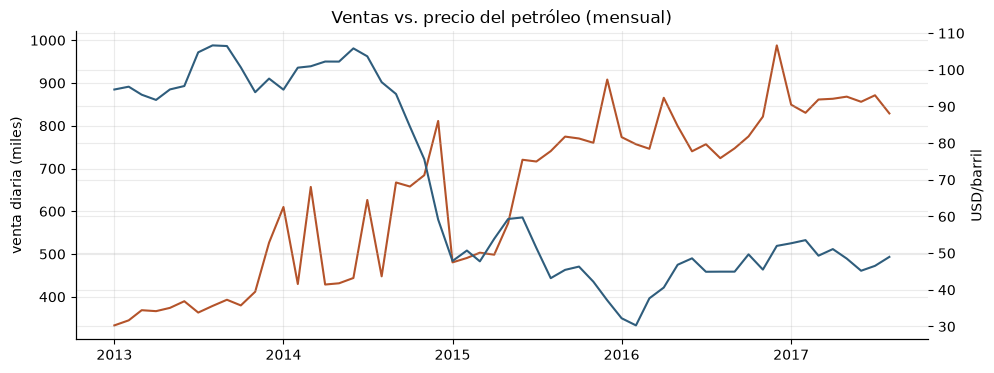

Correlación en niveles: -0.79 | correlación de variaciones interanuales: -0.16


In [9]:
o = a.oil_correlation(con)
m = o["monthly"]
fig, ax1 = plt.subplots(); ax2 = ax1.twinx()
ax1.plot(m.month, m.sales / 1e3, color=ACC, label="ventas"); ax2.plot(m.month, m.oil, color=BLU, label="WTI")
ax1.set_ylabel("venta diaria (miles)"); ax2.set_ylabel("USD/barril"); ax1.set_title("Ventas vs. precio del petróleo (mensual)")
plt.show()
print(f"Correlación en niveles: {o['corr_level']:+.2f} | correlación de variaciones interanuales: {o['corr_yoy']:+.2f}")

**Conclusión.** En niveles la correlación es fuerte y negativa (−0.79), pero es engañosa: el petróleo cayó de más de 100 a unos 30 USD justo cuando la cadena crecía por aperturas. Al comparar variaciones interanuales la relación casi desaparece (−0.16). Ecuador depende del petróleo, pero en este periodo no se ve un efecto claro sobre las ventas diarias; el modelo lo incluye y la importancia de variables dirá cuánto aporta.

## 9. Ranking de tiendas y familias

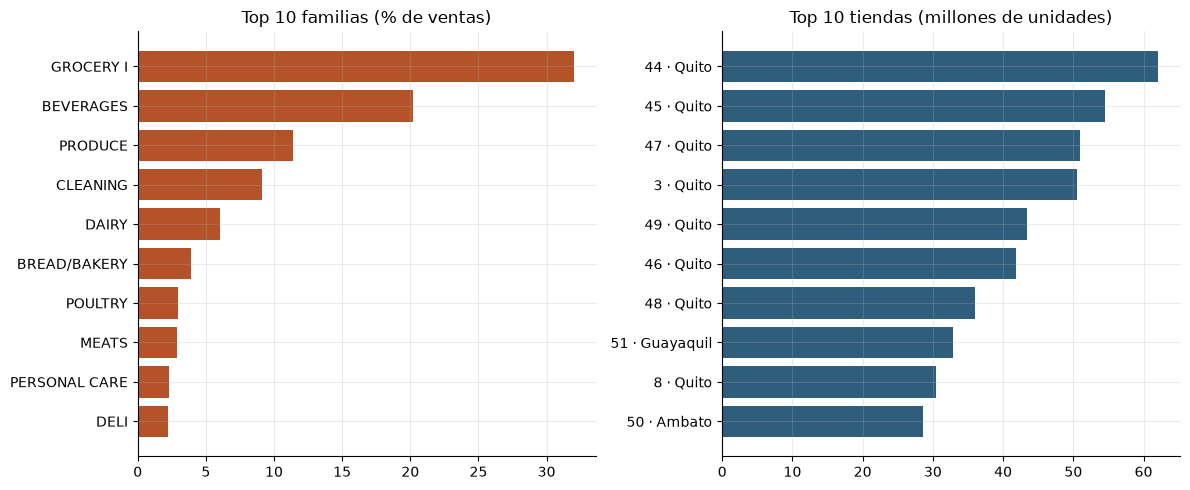

Top 5 familias = 78.7% de las ventas
Tiendas de Quito en el top 10: 8


,family,sales,share
0,GROCERY I,"343,462,734.886",0.320
1,BEVERAGES,"216,954,486.000",0.202
2,PRODUCE,"122,704,684.676",0.114
3,CLEANING,"97,521,289.000",0.091
4,DAIRY,"64,487,709.000",0.060


In [10]:
fam = con.execute("SELECT family, sales, share FROM gold.v_kpi_family ORDER BY sales DESC").df()
st = con.execute("SELECT store_nbr, city, state, store_type, sales FROM gold.v_kpi_store ORDER BY sales DESC").df()
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
f10 = fam.head(10).iloc[::-1]; ax[0].barh(f10.family, f10.share * 100, color=ACC); ax[0].set_title("Top 10 familias (% de ventas)")
s10 = st.head(10).iloc[::-1]; ax[1].barh(s10.store_nbr.astype(str) + " · " + s10.city, s10.sales / 1e6, color=BLU)
ax[1].set_title("Top 10 tiendas (millones de unidades)"); plt.tight_layout(); plt.show()
print(f"Top 5 familias = {fam.head(5).share.sum():.1%} de las ventas")
print(f"Tiendas de Quito en el top 10: {(st.head(10).city == 'Quito').sum()}")
fam.head(5)

**Conclusión.** Cinco familias (GROCERY I, BEVERAGES, PRODUCE, CLEANING y DAIRY) concentran el 79% de las unidades vendidas, así que el error del pronóstico en ellas es el que más pesa en un WAPE. Las tiendas más grandes son de Quito (8 de las 10 primeras). Ojo: las ventas están en unidades (y kilos en algunas familias), no en dólares.

## 10. Huecos de datos

In [11]:
cero = con.execute("""SELECT fam.family, avg((sales = 0)::INT) AS share_zero_days
                         FROM gold.fact_sales f JOIN gold.dim_family fam USING (family_id)
                         GROUP BY 1 ORDER BY 2 DESC LIMIT 8""").df()
cerradas = con.execute("""SELECT count(*) FROM (SELECT date, store_nbr FROM gold.fact_sales
                            GROUP BY ALL HAVING sum(sales) = 0)""").fetchone()[0]
aperturas = con.execute("""SELECT store_nbr, min(date) AS first_sale FROM gold.fact_sales WHERE sales > 0
                             GROUP BY 1 HAVING min(date) > DATE '2013-01-02' ORDER BY 2""").df()
print(f"Días-tienda con venta total cero: {cerradas:,}")
print(f"Tiendas que empiezan a vender después del 2-ene-2013: {len(aperturas)}")
cero

Días-tienda con venta total cero: 7,330
Tiendas que empiezan a vender después del 2-ene-2013: 8


,family,share_zero_days
0,BOOKS,0.970
1,BABY CARE,0.941
2,SCHOOL AND OFFICE SUPPLIES,0.741
3,HOME APPLIANCES,0.735
4,LADIESWEAR,0.598
5,MAGAZINES,0.565
6,PET SUPPLIES,0.546
7,HARDWARE,0.479


**Conclusión.** Hay 7,330 días-tienda con venta total cero: tiendas aún no abiertas o cerradas temporalmente; 8 tiendas empiezan a vender después del 2-ene-2013. Familias como BOOKS, BABY CARE o HOME APPLIANCES tienen ventas en cero la mayoría de los días, y antes de mediados de 2015 hay meses enteros sin registro (sección 1). Para el modelo esto significa: (1) entrenar desde julio de 2015, (2) dejar que el modelo aprenda los ceros a partir de los lags, y (3) pronosticar cero directamente para las series que no vendieron nada en los 28 días previos al corte.

## Resumen para el modelo
- Variables clave: día de la semana, mes y día del mes, días desde/hasta el pago, feriado nacional y feriado local por tienda, `onpromotion`, metadata de la tienda y petróleo.
- Lags ≥ 16 días (el horizonte) para no usar información que no estaría disponible al pronosticar.
- Entrenar desde julio de 2015 (registro estable) y evaluar con 3 cortes de 16 días al final.
- Las cifras entre años o meses usan las familias de registro estable; las comparaciones dentro del mismo mes usan todas.

In [12]:
con.close()